# 03 · Forecasting Water Stress to 2035

**Question:** which countries are heading toward *High* (75–100%) or *Critical* (>100%) water stress?

Water stress (UN SDG 6.4.2) = freshwater withdrawn ÷ freshwater available, in %.
Above 100% a country uses more water than nature renews, by drawing down groundwater or relying on desalination.

**Approach**
1. Use only *genuine* UN observations (drop years where the UN just repeated last year's value).
2. Back-test four forecasting models: train on the past, predict years the model never saw, measure the error.
3. Pick the model that is most accurate on held-out years, tune it, and calibrate its uncertainty range.
4. Forecast 2024–2035 and list the countries expected to cross the 75% and 100% thresholds.
5. Check which water uses (agriculture, industry, municipal) go with high stress.

Reusable logic lives in [`src/water_forecast.py`](../src/water_forecast.py); this notebook tells the story.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / 'src'))
import water_forecast as wf

FIG_DIR = ROOT / 'reports' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

master = pd.read_csv(ROOT / 'data' / 'processed' / 'Master_Global_Water_Dataset_2001_2023.csv')
print(f"Master dataset: {len(master):,} rows, {master['m49'].nunique()} countries, "
      f"{master['Year'].min()}-{master['Year'].max()}")

Master dataset: 4,181 rows, 183 countries, 2001-2023


## 1 · Genuine observations only

The UN does not survey every country every year; between surveys it repeats the last estimate.
`Stress_Carried_Forward` marks those repeats. If we kept them, a country with real data in 2005 and 2015
would look perfectly flat for the nine years in between, which would bias every trend toward zero.

We keep countries with `Stress_Forecastable = True` (at least 5 distinct values) and at least 5 genuine observations.

In [2]:
obs = wf.prepare_observations(master, min_obs=5)
n_all = master['m49'].nunique()
n_fc = obs['m49'].nunique()
print(f"Countries forecast: {n_fc} of {n_all}  |  genuine observations used: {len(obs):,}")
print(f"Carried-forward rows removed: {master['Stress_Carried_Forward'].sum():,} "
      f"({master['Stress_Carried_Forward'].mean():.0%} of all rows)")

last_obs = obs.groupby('m49')['Year'].max()
print('\nYear of each country\'s latest genuine observation:')
print(last_obs.value_counts().sort_index().to_string())

Countries forecast: 151 of 183  |  genuine observations used: 2,592
Carried-forward rows removed: 1,352 (32% of all rows)

Year of each country's latest genuine observation:
Year
2005    13
2006     2
2007     1
2008     1
2009     1
2010     3
2011     2
2012     5
2013     3
2014     3
2015     7
2016     6
2017     6
2018     3
2019     8
2020     7
2021    11
2022    23
2023    46


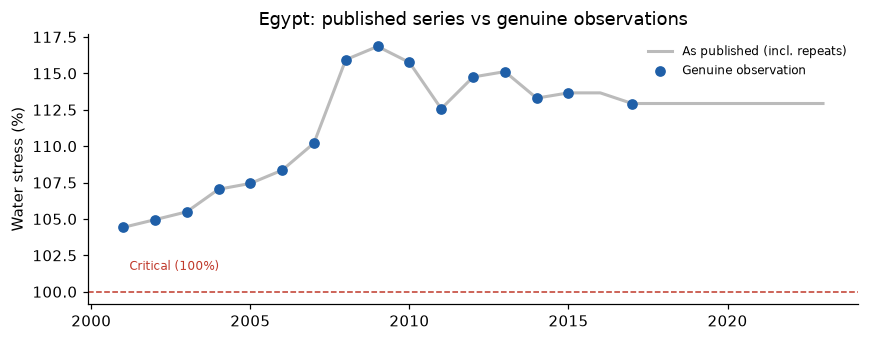

In [3]:
# Example: what carried-forward values look like
example = master[master['Country'] == 'Egypt'].set_index('Year')
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(example.index, example['Water_Stress_Total_Pct'], color='#bbb', lw=2, label='As published (incl. repeats)')
real = example[~example['Stress_Carried_Forward']]
ax.scatter(real.index, real['Water_Stress_Total_Pct'], color='#1f5fa8', zorder=3, label='Genuine observation')
ax.axhline(100, color='#c0392b', ls='--', lw=1)
ax.text(2001.2, 101.5, 'Critical (100%)', color='#c0392b', fontsize=8)
ax.set(title='Egypt: published series vs genuine observations', ylabel='Water stress (%)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fc_01_carried_forward_example.png'); plt.show()

## 2 · Back-test: which model actually predicts well?

Each model is trained on a country's observations **up to a cut-off year** and must predict that
country's genuine observations **after** it. Repeating this at three cut-offs (2015, 2016, 2018) checks
that the winner is not a fluke of one period.

| Model | Idea |
|---|---|
| Naive (last value) | Nothing changes. The baseline any model must beat. |
| Linear trend | Straight line through all observations since 2001. |
| Damped Holt | Exponential smoothing with a trend that fades out. |
| Damped recent trend | Start at the latest value, follow the slope of the last 8 observations, and let it fade. |

Errors are in **percentage points** of water stress.

In [4]:
CUTOFFS = [2015, 2016, 2018]
bt_by_cutoff = {c: wf.backtest(obs, train_end=c) for c in CUTOFFS}

summary = pd.concat({f'cut-off {c}': wf.summarise_backtest(bt) for c, bt in bt_by_cutoff.items()})
summary

MAE  Median_AE  Bias  Win_Rate_Pct  Countries
             Model                                                               
cut-off 2015 Damped recent trend   6.51       1.17  0.38         15.45        110
             Naive (last value)    6.74       1.12  0.42         37.27        110
             Damped Holt           7.69       1.27  0.57         29.09        110
             Linear trend         11.43       1.64  1.77         18.18        110
cut-off 2016 Damped recent trend   4.80       1.12 -0.28         22.12        104
             Naive (last value)    5.07       1.10 -0.10         28.85        104
             Damped Holt           5.81       1.24  0.14         33.65        104
             Linear trend          9.98       1.55  2.09         15.38        104
cut-off 2018 Damped recent trend   4.23       0.89  1.34         28.42         95
             Naive (last value)    4.38       0.94  1.65         28.42         95
             Damped Holt           5.42       1.02  1.84         31.58         95
             Linear trend          8.03       1.45  2.73         11.58         95

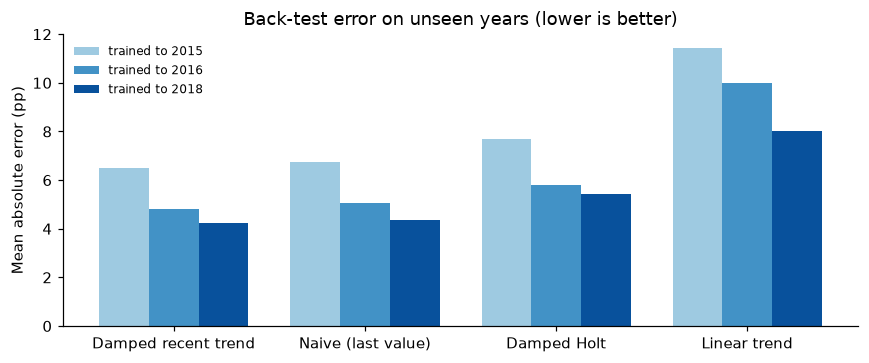

In [5]:
mae = pd.DataFrame({c: wf.summarise_backtest(bt)['MAE'] for c, bt in bt_by_cutoff.items()})
mae = mae.loc[mae.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 3.4))
x = np.arange(len(mae))
for i, c in enumerate(CUTOFFS):
    ax.bar(x + (i - 1) * 0.26, mae[c], width=0.26, label=f'trained to {c}',
           color=['#9ecae1', '#4292c6', '#08519c'][i])
ax.set_xticks(x, mae.index)
ax.set(ylabel='Mean absolute error (pp)', title='Back-test error on unseen years (lower is better)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fc_02_backtest_mae.png'); plt.show()

**Reading the back-test**

* The **full-history linear trend is the worst model** at every cut-off. Many countries' stress rose in the 2000s
  and then levelled off, so a straight line through 2001–2018 overshoots.
* The **naive baseline is hard to beat**: water stress changes slowly.
* The **damped recent trend** matches or beats the naive baseline on mean error at every cut-off, while still
  telling us *which direction* each country is moving. That direction is what the project question needs.
  It is our forecasting model.

## 3 · Tuning the damping factor φ

φ controls how fast the recent slope fades: φ = 0 is the naive model, φ = 1 is an undamped straight line.
To avoid tuning on the same data we report, φ is **chosen on the 2016 cut-off** and then **confirmed on 2018**.

In [6]:
phis = [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
tune = []
for phi in phis:
    row = {'phi': phi}
    for c in (2016, 2018):
        bt = wf.backtest(obs, train_end=c, models=['Damped recent trend'], phi=phi)
        row[f'MAE {c} (pp)'] = bt['Error'].abs().mean()
    tune.append(row)
tune = pd.DataFrame(tune).set_index('phi').round(3)
best_phi = tune['MAE 2016 (pp)'].idxmin()
print(f'Best phi on the 2016 cut-off: {best_phi}  (module default: {wf.DEFAULT_PHI})')
tune

Best phi on the 2016 cut-off: 0.5  (module default: 0.5)


,MAE 2016 (pp),MAE 2018 (pp)
phi,,
0.0,5.068,4.383
0.5,4.797,4.230
0.6,4.820,4.208
0.7,4.901,4.212
0.8,5.027,4.252
0.9,5.179,4.350
1.0,5.437,4.493


In [7]:
PHI = float(best_phi)
PHI_TREND = wf.TREND_PHI
print(f"Base forecast: phi = {PHI}. Total future change is capped at "
      f"{PHI / (1 - PHI) if PHI < 1 else float('inf'):.1f} years' worth of the recent slope.")

Base forecast: phi = 0.5. Total future change is capped at 1.0 years' worth of the recent slope.


**What the tuning tells us.** Every φ between 0.3 and 0.9 beats the naive baseline at *all three* cut-offs,
so recent trends carry real information. But the error is lowest with strong damping (φ ≈ 0.5): historically,
water stress trends have tended to **slow down rather than continue**.

We therefore report two views:

* **Base forecast (φ = 0.5):** the most accurate model on held-out data. Our best estimate.
* **"Recent trend continues" scenario (φ = 1):** a *stress test*, not a prediction. What happens if the last
  8 observations' trend does not slow down? Useful for planning: it shows which countries are on a dangerous path.

## 4 · How uncertain are the forecasts?

Rather than trusting a textbook formula, the uncertainty range is **estimated from the model's own back-test errors**.
The spread of errors grows with the forecast horizon *h*, so we fit `sd(h) = s·√h` on the log scale.

We then **check the range honestly**: *s* is estimated on the 2015 and 2016 back-tests, and we count how often
the 2018 back-test's actual values fall inside the resulting 80% range. A well-calibrated range should contain ≈ 80% of them.

In [8]:
bt_fit = pd.concat([wf.backtest(obs, train_end=c, models=['Damped recent trend'], phi=PHI) for c in (2015, 2016)])
s_fit = wf.interval_scale(bt_fit)

check = wf.backtest(obs, train_end=2018, models=['Damped recent trend'], phi=PHI)
spread = 1.2816 * s_fit * np.sqrt(check['Horizon'])
lo = np.expm1(np.log1p(check['Predicted']) - spread)
hi = np.expm1(np.log1p(check['Predicted']) + spread)
coverage = ((check['Actual'] >= lo) & (check['Actual'] <= hi)).mean()
print(f'Log-scale error growth s = {s_fit:.4f}')
print(f'80% range coverage on the unseen 2018 back-test: {coverage:.1%}  (target 80%)')

Log-scale error growth s = 0.1278
80% range coverage on the unseen 2018 back-test: 87.4%  (target 80%)


In [9]:
# Final uncertainty scale: pooled over all three cut-offs
bt_all = pd.concat([wf.backtest(obs, train_end=c, models=['Damped recent trend'], phi=PHI) for c in CUTOFFS])
S = wf.interval_scale(bt_all)
print(f'Final s used for forecasts: {S:.4f}')

Final s used for forecasts: 0.1335


## 5 · Forecast 2024–2035

In [10]:
forecast = wf.forecast_all(obs, master, log_sd_scale=S, first_year=2024, last_year=2035, phi=PHI)

latest = (master.dropna(subset=['Water_Stress_Total_Pct'])
          .sort_values('Year').groupby('m49').tail(1)
          [['m49', 'Country', 'Year', 'Water_Stress_Total_Pct']]
          .rename(columns={'Year': 'Latest_Year', 'Water_Stress_Total_Pct': 'Latest_Stress_Pct'}))

trend = wf.forecast_all(obs, master, log_sd_scale=S, first_year=2024, last_year=2035, phi=PHI_TREND)
forecast['Trend_Continues_Pct'] = trend['Forecast_Stress_Pct'].to_numpy()

forecast = forecast.merge(latest[['m49', 'Latest_Stress_Pct']], on='m49')
forecast['Change_vs_Latest_pp'] = (forecast['Forecast_Stress_Pct'] - forecast['Latest_Stress_Pct']).round(2)
forecast.head()

,m49,ISO3_Code,Country,Year,Last_Observed_Year,Forecast_Stress_Pct,Lower_80_Pct,Upper_80_Pct,Forecast_Category,Trend_Continues_Pct,Latest_Stress_Pct,Change_vs_Latest_pp
0,8,ALB,Albania,2024,2023,4.70,3.81,5.77,1. No Stress (<25%),4.61,4.8,-0.10
1,8,ALB,Albania,2025,2023,4.66,3.44,6.20,1. No Stress (<25%),4.42,4.8,-0.14
2,8,ALB,Albania,2026,2023,4.63,3.19,6.57,1. No Stress (<25%),4.22,4.8,-0.17
3,8,ALB,Albania,2027,2023,4.62,2.99,6.91,1. No Stress (<25%),4.03,4.8,-0.18
4,8,ALB,Albania,2028,2023,4.61,2.83,7.23,1. No Stress (<25%),3.84,4.8,-0.19


In [11]:
tiers = [t for _, t in wf.STRESS_TIERS]
fc_ids = obs['m49'].unique()
now = latest[latest['m49'].isin(fc_ids)]['Latest_Stress_Pct'].apply(wf.stress_category).value_counts()
y30 = forecast[forecast['Year'] == 2030]['Forecast_Category'].value_counts()
y35 = forecast[forecast['Year'] == 2035]['Forecast_Category'].value_counts()
t35 = forecast[forecast['Year'] == 2035]['Trend_Continues_Pct'].apply(wf.stress_category).value_counts()
tier_table = (pd.DataFrame({'Latest': now, '2030': y30, '2035': y35, '2035 (trend continues)': t35})
              .reindex(tiers).fillna(0).astype(int))
tier_table

,Latest,2030,2035,2035 (trend continues)
1. No Stress (<25%),96,95,95,95
2. Low Stress (25-50%),24,25,25,18
3. Medium Stress (50-75%),10,10,10,12
4. High Stress (75-100%),6,6,6,7
5. Critical Stress (>100%),15,15,15,19


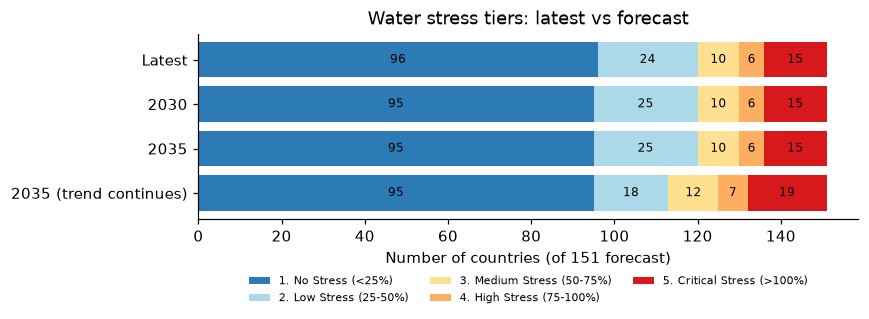

In [12]:
colors = ['#2c7bb6', '#abd9e9', '#fee090', '#fdae61', '#d7191c']
fig, ax = plt.subplots(figsize=(8, 3.2))
left = np.zeros(len(tier_table.columns))
for tier, col in zip(tiers, colors):
    vals = tier_table.loc[tier].to_numpy()
    ax.barh(tier_table.columns, vals, left=left, color=col, label=tier)
    for i, v in enumerate(vals):
        if v >= 6:
            ax.text(left[i] + v / 2, i, str(v), ha='center', va='center', fontsize=8)
    left += vals
ax.invert_yaxis()
ax.set(xlabel=f'Number of countries (of {len(fc_ids)} forecast)', title='Water stress tiers: latest vs forecast')
ax.legend(frameon=False, fontsize=7, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.25))
fig.tight_layout(); fig.savefig(FIG_DIR / 'fc_03_tiers_latest_vs_forecast.png', bbox_inches='tight'); plt.show()

## 6 · Countries heading toward High and Critical stress

For every country that is **currently below** a threshold we report:

* **Chance above in 2035:** probability that 2035 stress exceeds the threshold, from the base forecast and its
  back-test-calibrated uncertainty range.
* **Base crossing year:** first year the base forecast reaches the threshold (blank if it does not by 2035).
* **Crossing if trend continues:** the same under the undamped stress-test scenario.

The list keeps countries with at least a 20% chance, or that cross under either view.

In [13]:
crossings_base = wf.threshold_crossings(forecast, latest)
trend_fc = forecast[['m49', 'ISO3_Code', 'Country', 'Year']].assign(Forecast_Stress_Pct=forecast['Trend_Continues_Pct'])
crossings_trend = wf.threshold_crossings(trend_fc, latest)

f35 = forecast[forecast['Year'] == 2035].set_index('m49')
rows = []
for thr, label in ((wf.CRITICAL_THRESHOLD, 'Critical (100%)'), (wf.HIGH_THRESHOLD, 'High (75%)')):
    for m49, r in f35[f35['Latest_Stress_Pct'] < thr].iterrows():
        chance = wf.chance_above(r['Forecast_Stress_Pct'], thr, S, 2035 - r['Last_Observed_Year'])
        base_year = crossings_base.query('m49 == @m49 and Threshold_Pct == @thr')['Crossing_Year']
        trend_year = crossings_trend.query('m49 == @m49 and Threshold_Pct == @thr')['Crossing_Year']
        rows.append({'Threshold': label, 'Country': r['Country'], 'ISO3_Code': r['ISO3_Code'],
                     'Last_Real_Data_Year': int(r['Last_Observed_Year']),
                     'Latest_Stress_Pct': r['Latest_Stress_Pct'],
                     'Base_2035_Pct': r['Forecast_Stress_Pct'], 'Trend_Continues_2035_Pct': r['Trend_Continues_Pct'],
                     'Chance_Above_2035_Pct': round(chance),
                     'Base_Crossing_Year': base_year.iloc[0] if len(base_year) else pd.NA,
                     'Crossing_If_Trend_Continues': trend_year.iloc[0] if len(trend_year) else pd.NA})
risk = pd.DataFrame(rows)
at_risk = risk[(risk['Chance_Above_2035_Pct'] >= 20) | risk['Base_Crossing_Year'].notna()
               | risk['Crossing_If_Trend_Continues'].notna()]
at_risk = at_risk.sort_values(['Threshold', 'Chance_Above_2035_Pct'], ascending=[True, False]).reset_index(drop=True)
print(f"Countries at risk of reaching Critical: {(at_risk['Threshold'] == 'Critical (100%)').sum()}  |  "
      f"High: {(at_risk['Threshold'] == 'High (75%)').sum()}")
at_risk

Countries at risk of reaching Critical: 14  |  High: 15


,Threshold,Country,ISO3_Code,Last_Real_Data_Year,Latest_Stress_Pct,Base_2035_Pct,Trend_Continues_2035_Pct,Chance_Above_2035_Pct,Base_Crossing_Year,Crossing_If_Trend_Continues
0,Critical (100%),Tunisia,TUN,2023,97.05,97.42,101.46,48,<NA>,2032
1,Critical (100%),Pakistan,PAK,2023,98.12,95.23,63.47,46,<NA>,<NA>
2,Critical (100%),Sri Lanka,LKA,2005,90.79,90.70,88.09,45,<NA>,<NA>
3,Critical (100%),Republic of Korea,KOR,2005,85.22,85.68,98.93,42,<NA>,<NA>
4,Critical (100%),Eswatini,SWZ,2005,77.56,77.94,88.87,37,<NA>,<NA>
5,Critical (100%),Iran (Islamic Republic of),IRN,2020,80.43,78.69,54.33,32,<NA>,<NA>
6,Critical (100%),Tajikistan,TJK,2019,69.94,68.85,52.53,24,<NA>,<NA>
7,Critical (100%),Iraq,IRQ,2022,67.81,70.34,100.70,23,<NA>,2035
8,Critical (100%),South Africa,ZAF,2022,67.60,68.73,82.24,22,<NA>,<NA>
9,Critical (100%),North Macedonia,MKD,2023,65.88,69.54,109.77,22,<NA>,2033


**How to read this table**

* The **base forecast crosses no new threshold by 2035**: with the damping that back-testing favours, countries
  move slowly. Risk shows up instead as *probability*. **Tunisia and Pakistan** (both with data to 2023, both just
  under 100% today) have close to a 50% chance of being in Critical stress by 2035. Sri Lanka, the Republic of Korea
  and Eswatini also score high, but their latest real data is from 2005, so most of that chance reflects uncertainty.
* The **trend-continues** column shows which countries are on a steep path (e.g. Iraq, North Macedonia, Lebanon,
  Cabo Verde, Mali would pass 100%).
* Check **`Last_Real_Data_Year`**: where it is old (e.g. 2010), the UN has published no new estimate since, and any
  trend, especially the trend-continues scenario, rests on old data.

In [14]:
already = latest[latest['Latest_Stress_Pct'] >= wf.CRITICAL_THRESHOLD].sort_values('Latest_Stress_Pct', ascending=False)
print(f'{len(already)} countries are ALREADY in Critical stress (>100%) on their latest data:')
already[['Country', 'Latest_Year', 'Latest_Stress_Pct']].reset_index(drop=True)

16 countries are ALREADY in Critical stress (>100%) on their latest data:


,Country,Latest_Year,Latest_Stress_Pct
0,Kuwait,2023,3850.50
1,United Arab Emirates,2023,1437.33
2,Saudi Arabia,2023,974.17
3,Libya,2023,817.14
4,Qatar,2023,431.03
5,Yemen,2023,281.48
6,Bahrain,2023,152.50
7,Algeria,2023,144.81
8,Turkmenistan,2023,135.21
9,Syrian Arab Republic,2023,124.36


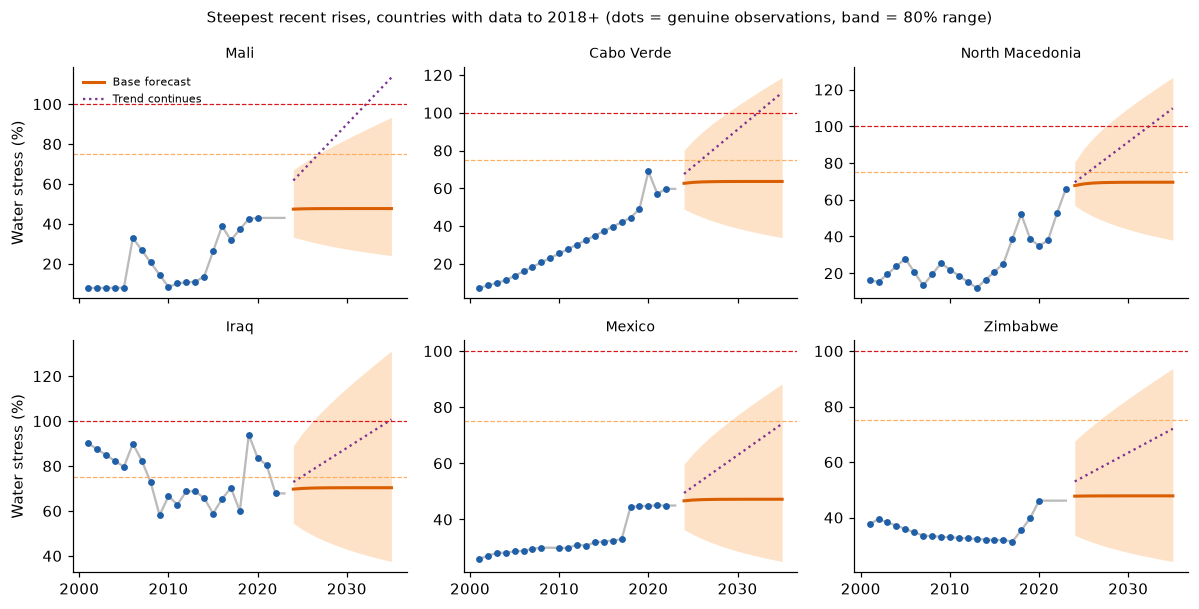

In [15]:
# Fan charts: countries below 100% today with the steepest recent rise (largest 2035 value if the trend continues)
# only countries with recent real data (2018+), so the trend reflects the current situation
f35_all = forecast[(forecast['Year'] == 2035) & (forecast['Latest_Stress_Pct'] < 100)
                   & (forecast['Last_Observed_Year'] >= 2018)].copy()
f35_all['Trend_Rise_pp'] = f35_all['Trend_Continues_Pct'] - f35_all['Latest_Stress_Pct']
risers = f35_all.nlargest(6, 'Trend_Rise_pp')['m49'].tolist()

fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True)
for ax, m49 in zip(axes.flat, risers):
    hist = master[master['m49'] == m49]
    real = obs[obs['m49'] == m49]
    fc = forecast[forecast['m49'] == m49]
    ax.plot(hist['Year'], hist['Water_Stress_Total_Pct'], color='#bbb', lw=1.5)
    ax.scatter(real['Year'], real['Stress'], s=12, color='#1f5fa8', zorder=3)
    ax.fill_between(fc['Year'], fc['Lower_80_Pct'], fc['Upper_80_Pct'], color='#fdae61', alpha=0.35, lw=0)
    ax.plot(fc['Year'], fc['Forecast_Stress_Pct'], color='#d95f02', lw=2, label='Base forecast')
    ax.plot(fc['Year'], fc['Trend_Continues_Pct'], color='#7b3294', lw=1.5, ls=':', label='Trend continues')
    for thr, col in ((75, '#fdae61'), (100, '#d7191c')):
        ax.axhline(thr, color=col, ls='--', lw=0.8)
    ax.set_title(hist['Country'].iloc[0], fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel('Water stress (%)')
axes.flat[0].legend(frameon=False, fontsize=7, loc='upper left')
fig.suptitle('Steepest recent rises, countries with data to 2018+ (dots = genuine observations, band = 80% range)', fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fc_04_top_risers.png'); plt.show()

## 7 · What goes with high water stress? (correlation & regression)

A cross-sectional look at each country's latest complete year: is high stress linked to *how* a country uses its water?
Stress is heavily skewed (from under 1% to several thousand %), so we model **log(stress)** and use Spearman rank
correlation, which is robust to outliers.

In [16]:
cols = ['Water_Stress_Total_Pct', 'Agri_Share_Pct', 'Ind_Share_Pct', 'Mun_Share_Pct', 'Total_Withdrawal_FAO_10e9_m3']
xs = (master.dropna(subset=cols).sort_values('Year').groupby('m49').tail(1).copy())
xs = xs[xs['Water_Stress_Total_Pct'] > 0]
xs['log_stress'] = np.log10(xs['Water_Stress_Total_Pct'])
print(f'Countries in cross-section: {len(xs)} (latest year with complete data)')

rows = []
for c in ['Agri_Share_Pct', 'Ind_Share_Pct', 'Mun_Share_Pct']:
    rho, p = stats.spearmanr(xs[c], xs['Water_Stress_Total_Pct'])
    rows.append({'Variable': c, 'Spearman_rho': round(rho, 3), 'p_value': f'{p:.2g}'})
pd.DataFrame(rows)

Countries in cross-section: 176 (latest year with complete data)


,Variable,Spearman_rho,p_value
0,Agri_Share_Pct,0.290,9.4e-05
1,Ind_Share_Pct,-0.238,0.0015
2,Mun_Share_Pct,-0.307,3.4e-05


In [17]:
# Agriculture and industry shares; municipal share is the omitted reference (shares sum to ~100%)
model = smf.ols('log_stress ~ Agri_Share_Pct + Ind_Share_Pct', data=xs).fit(cov_type='HC3')
print(model.summary().tables[1])
print(f'R² = {model.rsquared:.3f},  n = {int(model.nobs)}')
b = model.params['Agri_Share_Pct']
print(f'\nInterpretation: +10 percentage points of agricultural share goes with water stress '
      f'x{10 ** (10 * b):.2f} (holding industry share fixed), relative to municipal use.')

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          0.5736      0.215      2.672      0.008       0.153       0.994
Agri_Share_Pct     0.0077      0.003      2.938      0.003       0.003       0.013
Ind_Share_Pct      0.0015      0.003      0.422      0.673      -0.005       0.008
R² = 0.080,  n = 176

Interpretation: +10 percentage points of agricultural share goes with water stress x1.19 (holding industry share fixed), relative to municipal use.


**Reading the regression.** Countries that use a larger share of their water for agriculture tend to be more stressed
(Spearman ρ ≈ 0.29, p < 0.001; regression coefficient significant at p ≈ 0.003). But the effect is **modest and explains
little of the variation (R² ≈ 0.08)**: *how much* water a country has matters far more than *how it splits* its use.
Arid Gulf states are critical whatever their sector mix. Industry share adds nothing once agriculture is known.

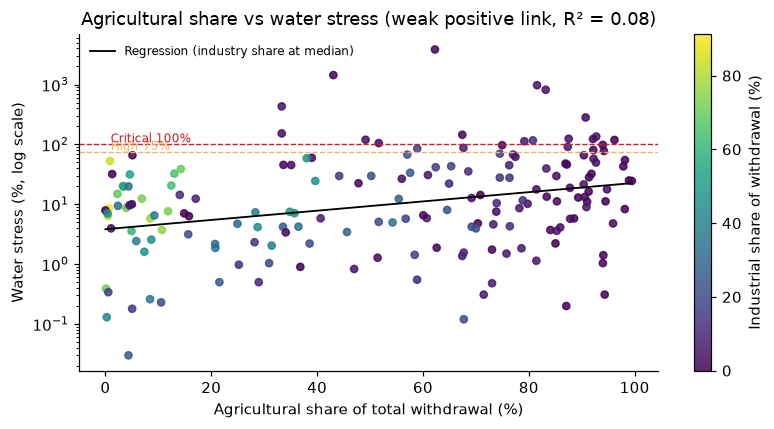

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 4))
sc = ax.scatter(xs['Agri_Share_Pct'], xs['Water_Stress_Total_Pct'], c=xs['Ind_Share_Pct'],
                cmap='viridis', s=22, alpha=0.85)
ax.set_yscale('log')
for thr, col, lab in ((75, '#fdae61', 'High 75%'), (100, '#d7191c', 'Critical 100%')):
    ax.axhline(thr, color=col, ls='--', lw=0.9)
    ax.text(1, thr * 1.08, lab, color=col, fontsize=8)
grid = np.linspace(xs['Agri_Share_Pct'].min(), xs['Agri_Share_Pct'].max(), 50)
pred = model.predict(pd.DataFrame({'Agri_Share_Pct': grid, 'Ind_Share_Pct': xs['Ind_Share_Pct'].median()}))
ax.plot(grid, 10 ** pred, color='black', lw=1.2, label='Regression (industry share at median)')
fig.colorbar(sc, ax=ax, label='Industrial share of withdrawal (%)')
ax.set(xlabel='Agricultural share of total withdrawal (%)', ylabel='Water stress (%, log scale)',
       title='Agricultural share vs water stress (weak positive link, R² = 0.08)')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fc_05_agri_share_vs_stress.png'); plt.show()

## 8 · Limitations

* **Sparse, partly modelled data.** Many UN values are *estimated* or *imputed* (`Stress_Obs_Status` E/I), not reported.
  Forecasts can only be as good as these inputs.
* **Trend extrapolation, not a causal model.** The forecast assumes recent tendencies continue and fade. It cannot see
  policy changes, droughts, new desalination plants or population shocks.
* **Damping is deliberately conservative.** The back-test showed that bold straight-line trends lose to "no change";
  the tuned base model moves countries slowly. The *trend continues* scenario is shown alongside so that slowly building
  risks are not hidden; it is a stress test, not a prediction.
* **32 countries are not forecast** because their published series has too little real variation.
* **Old data for some countries.** For several countries the latest genuine UN observation is 2005–2015
  (`Last_Observed_Year` in the forecast file). Their forecasts extrapolate from that point and should be read with care.
* **Average error vs. typical error.** The damped recent trend has the lowest *average* error because it avoids large misses;
  the naive model is right more often for countries that barely change (see `Win_Rate_Pct`).
* **Correlation is not causation.** The regression shows association across countries, not that changing the
  agricultural share would change stress.

## 9 · Save outputs for the dashboard and report

In [19]:
proc = ROOT / 'data' / 'processed'
rep = ROOT / 'reports'
forecast.to_csv(proc / 'Water_Stress_Forecast_2024_2035.csv', index=False, encoding='utf-8-sig')
at_risk.to_csv(rep / '06_Countries_At_Risk_2035.csv', index=False, encoding='utf-8-sig')
summary.to_csv(rep / '07_Forecast_Backtest_Metrics.csv', encoding='utf-8-sig')
for p in ['data/processed/Water_Stress_Forecast_2024_2035.csv', 'reports/06_Countries_At_Risk_2035.csv',
          'reports/07_Forecast_Backtest_Metrics.csv']:
    print('saved', p)
print('figures in reports/figures/:', sorted(f.name for f in FIG_DIR.glob('fc_*.png')))

saved data/processed/Water_Stress_Forecast_2024_2035.csv
saved reports/06_Countries_At_Risk_2035.csv
saved reports/07_Forecast_Backtest_Metrics.csv
figures in reports/figures/: ['fc_01_carried_forward_example.png', 'fc_02_backtest_mae.png', 'fc_03_tiers_latest_vs_forecast.png', 'fc_04_top_risers.png', 'fc_05_agri_share_vs_stress.png']
